# 2 · Table 1 and Figures 1D, 2 and 3

This page reproduces the results of the main text. It starts from the
two files written by the first page ([Data and
measures](01_data_and_measures.ipynb)):
`data/generated/analysis_dyads.csv`, one row per decision with the
Cooperation GAP, friendship type and Social Rank GAP already computed,
and `data/generated/analysis_students.csv`, one row per child.

The page follows the order of the paper:

1.  **Table 1**: how the Cooperation GAP changes with the Social Rank
    GAP, in each type of relationship.
2.  **Figure 1D**: a check that partners were indeed assigned at random
    with respect to rank.
3.  **Figure 2**: what the four networks look like in one small
    classroom.
4.  **Figure 3**: the exchanges behind the regressions, plotted
    directly.
5.  **Other numbers quoted in the text.**

# Table 1: the rank gradient in cooperation

## What we want to measure

Take one decision: child $i$ meets classmate $j$. Two things describe
the pair:

-   the **Social Rank GAP**, $\text{Rank}_i - \text{Rank}_j$, between
    $-1$ and $1$. It is positive when $i$ is the higher-ranked child of
    the two;
-   the **Cooperation GAP**, tokens $i$ received from $j$ minus tokens
    $i$ sent to $j$, between $-10$ and $10$. It is positive when $i$
    came out ahead.

If cooperation were blind to rank, the Cooperation GAP would be
unrelated to the rank gap. If lower-ranked children give more to
higher-ranked classmates than they get back, the Cooperation GAP rises
with the rank gap. The slope of that relation is the quantity of
interest.

Each pair appears twice in the data, once from each side, with both gaps
changing sign. This is what we want: every child is a sender in some
rows, and the model compares the same sender across her different
partners.

## The model

For a decision of sender $i$ toward partner $j$, in classroom $c$ and
round $t$:

$$
\text{Coop GAP}_{ijct} = \beta\, \text{RankGAP}_{ij} + \eta_i + \kappa_{c \times t} + u_{ijct}
$$

Each term has a job:

-   $\eta_i$, **sender fixed effects**. Some children are generous with
    everyone, others with no one. The sender fixed effect absorbs each
    child’s own level, so $\beta$ is estimated only from how the *same*
    child’s exchanges differ across her partners.
-   $\kappa_{c\times t}$, **classroom-by-round fixed effects**. A
    classroom may be more cooperative overall, and giving may drift
    during the session. These fixed effects compare only decisions made
    in the same classroom and round, the unit within which partners were
    drawn at random.
-   **Standard errors clustered by classroom.** Decisions from the same
    classroom share children, teachers and nomination networks, so they
    are not independent. Clustering by classroom (45 clusters) allows
    for any correlation within a classroom.

Because partners were assigned at random within each classroom and
round, the rank of the partner a child met is unrelated to her own
characteristics (Figure 1D below checks this). So $\beta$ can be read as
how the same child’s exchanges change when she happens to meet a higher-
or lower-ranked classmate.

The model is estimated separately in five samples, one per column of
Table 1: all pairs, non-friends, mutual friends, and the two kinds of
one-sided friendships, seen from the side of the child who named the
other: a lower-ranked child naming a higher-ranked one (L→H) or the
reverse (H→L).

In [ ]:
here::i_am("notebooks/main/02_main_results.qmd")
library(tidyverse)
library(lfe)      # felm(): linear models with many fixed effects
library(here)

dyads <- read_csv(here("data", "generated", "analysis_dyads.csv"), show_col_types = FALSE) %>%
  mutate(class_round = paste(class_id, round, sep = "_"),   # one code per classroom x round
         across(c(sender_id, class_id, class_round), as.factor))

In [ ]:
# Five samples, one per column of Table 1.
#
# One-sided friendships are seen from the side of the child who named the
# other ("Sender declares"), and split by who has the higher rank:
#   L -> H : the lower-ranked child names the higher-ranked one (rank_gap < 0)
#   H -> L : the higher-ranked child names the lower-ranked one (rank_gap > 0)
# Two of these 1,300 pairs have exactly the same rank (rank_gap = 0). As in
# the paper, they are counted in the H -> L column.

samples <- list(
  "All dyads"      = dyads,
  "Non-friends"    = dyads %>% filter(friendship == "Non-friends"),
  "Mutual friends" = dyads %>% filter(friendship == "Mutual"),
  "Asym. (L->H)"   = dyads %>% filter(friendship == "Sender declares", rank_gap < 0),
  "Asym. (H->L)"   = dyads %>% filter(friendship == "Sender declares", rank_gap >= 0)
)

sapply(samples, nrow)
##      All dyads    Non-friends Mutual friends   Asym. (L->H)   Asym. (H->L) 
##          17804          13916           1288            894            406

The two one-sided samples are small (fewer than 1,000 decisions each,
and few decisions per classroom and round), so they use classroom fixed
effects instead of classroom-by-round fixed effects.

The function `felm()` from the package **lfe** estimates linear models
with many fixed effects. Its formula has four parts separated by `|`:
the regression, the fixed effects, instruments (none here, `0`) and the
variable that defines the clusters.

In [ ]:
# Linear regression with fixed effects, standard errors clustered by classroom.
#
#   Coop GAP_ij = beta * RankGAP_ij + sender FE + classroom-by-round FE
#
# felm formula:  outcome ~ regressor | fixed effects | (no IV) 0 | cluster
#
# The two asymmetric samples are small, so they use classroom FE instead of
# classroom-by-round FE.

with_class_round <- coop_gap ~ rank_gap | sender_id + class_round | 0 | class_id
with_class       <- coop_gap ~ rank_gap | sender_id + class_id    | 0 | class_id

models <- list(
  "All dyads"      = felm(with_class_round, data = samples[["All dyads"]]),
  "Non-friends"    = felm(with_class_round, data = samples[["Non-friends"]]),
  "Mutual friends" = felm(with_class_round, data = samples[["Mutual friends"]]),
  "Asym. (L->H)"   = felm(with_class,       data = samples[["Asym. (L->H)"]]),
  "Asym. (H->L)"   = felm(with_class,       data = samples[["Asym. (H->L)"]])
)

summary(models[["Non-friends"]])
## 
## Call:
##    felm(formula = with_class_round, data = samples[["Non-friends"]]) 
## 
## Residuals:
##      Min       1Q   Median       3Q      Max 
## -15.4848  -2.6283  -0.2574   2.6179  17.3630 
## 
## Coefficients:
##          Estimate Cluster s.e. t value Pr(>|t|)    
## rank_gap   2.5615       0.2813   9.104 1.11e-11 ***
## ---
## Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1
## 
## Residual standard error: 4.3 on 12031 degrees of freedom
## Multiple R-squared(full model): 0.2968   Adjusted R-squared: 0.1866 
## Multiple R-squared(proj model): 0.02085   Adjusted R-squared: -0.1325 
## F-statistic(full model, *iid*):2.695 on 1884 and 12031 DF, p-value: < 2.2e-16 
## F-statistic(proj model): 82.89 on 1 and 44 DF, p-value: 1.111e-11

## Panel B: effects in more intuitive units

A slope of $\beta$ tokens per unit of rank gap is hard to picture,
because a full unit (from the bottom to the top of a classroom) is rare.
Panel B expresses the same estimate in three other ways:

-   **in tokens**, for a typical difference in rank (one standard
    deviation of the Social Rank GAP);
-   **in standard deviations of the Cooperation GAP**, which makes the
    effect comparable across samples;
-   **model-adjusted**, using only the variation in the rank gap that
    remains after removing the fixed effects. This is the variation the
    model actually uses, so this number is the most conservative of the
    three.

In [ ]:
# Panel B puts beta in more intuitive units:
#
#   effect in tokens     = beta * SD(Social Rank GAP)
#   effect in SD tokens  = beta * SD(Social Rank GAP) / SD(Cooperation GAP)
#   model-adjusted       = beta * SD(Social Rank GAP after removing the fixed
#                          effects) / SD(Cooperation GAP)
#
# The last one uses only the part of the rank gap that the fixed-effects
# model actually uses (its variation within sender and within class-round).

fixed_effects_used <- list(
  "All dyads"      = c("sender_id", "class_round"),
  "Non-friends"    = c("sender_id", "class_round"),
  "Mutual friends" = c("sender_id", "class_round"),
  "Asym. (L->H)"   = c("sender_id", "class_id"),
  "Asym. (H->L)"   = c("sender_id", "class_id")
)

rank_gap_within <- function(data, fixed_effects) {
  # demeanlist() removes the fixed effects from a variable
  demeaned <- demeanlist(list(data$rank_gap), as.list(data[, fixed_effects]))
  demeaned[[1]]
}

## Regression results

### Coefficient summary by sample

One row per sample, with the estimated slope, standard error, model fit,
and effect sizes.

In [ ]:
stars <- function(p) {
  case_when(p < 0.001 ~ "***", p < 0.01 ~ "**", p < 0.05 ~ "*", TRUE ~ "")
}

table1 <- map_dfr(names(models), function(name) {
  model   <- models[[name]]
  data    <- samples[[name]]
  results <- summary(model)
  beta    <- coef(model)[["rank_gap"]]

  tibble(
    sample   = name,
    beta     = beta,
    se       = results$coefficients["rank_gap", "Cluster s.e."],
    p_value  = results$coefficients["rank_gap", "Pr(>|t|)"],
    n        = model$N,
    r2       = results$r.squared,
    r2_adj   = results$adj.r.squared,
    effect_tokens          = beta * sd(data$rank_gap),
    effect_sd_tokens       = beta * sd(data$rank_gap) / sd(data$coop_gap),
    effect_sd_model_adjust = beta * sd(rank_gap_within(data, fixed_effects_used[[name]])) /
                             sd(data$coop_gap)
  )
})

table1 %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

sample,beta,se,p_value,n,r2,r2_adj,effect_tokens,effect_sd_tokens,effect_sd_model_adjust
All dyads,2.584,0.274,0.000,17804,0.275,0.189,0.916,0.193,0.131
Non-friends,2.562,0.281,0.000,13916,0.297,0.187,0.923,0.194,0.122
Mutual friends,1.069,1.327,0.425,1288,0.839,0.077,0.315,0.074,0.017
Asym. (L->H),3.066,1.105,0.008,894,0.672,0.256,0.671,0.144,0.089
Asym. (H->L),3.520,3.667,0.342,406,0.838,0.352,0.613,0.132,0.051


### Table 1. Results in the manuscript layout

Each column corresponds to a sample. Standard errors are shown in
parentheses.

In [ ]:
# The same numbers, laid out as Table 1 (one column per sample)
table1_display <- table1 %>%
  transmute(
    sample,
    `Social Rank GAP`           = paste0(sprintf("%.2f", beta), stars(p_value)),
    `(SE)`                      = sprintf("(%.2f)", se),
    Observations                = format(n, big.mark = ",", trim = TRUE),
    `R2`                        = sprintf("%.3f", r2),
    `R2 adj.`                   = sprintf("%.3f", r2_adj),
    `Effect in tokens`          = paste0(sprintf("%.2f", effect_tokens), stars(p_value)),
    `Effect in SD tokens`       = paste0(sprintf("%.3f", effect_sd_tokens), stars(p_value)),
    `Effect in SD (model-adj.)` = paste0(sprintf("%.3f", effect_sd_model_adjust), stars(p_value))
  ) %>%
  pivot_longer(-sample, names_to = "row") %>%
  pivot_wider(names_from = sample, values_from = value)

table1_display

row,All dyads,Non-friends,Mutual friends,Asym. (L->H),Asym. (H->L)
Social Rank GAP,2.58***,2.56***,1.07,3.07**,3.52
(SE),(0.27),(0.28),(1.33),(1.11),(3.67)
Observations,"17,804","13,916","1,288",894,406
R2,0.275,0.297,0.839,0.672,0.838
R2 adj.,0.189,0.187,0.077,0.256,0.352
Effect in tokens,0.92***,0.92***,0.32,0.67**,0.61
Effect in SD tokens,0.193***,0.194***,0.074,0.144**,0.132
Effect in SD (model-adj.),0.131***,0.122***,0.017,0.089**,0.051


**How to read it.** Among non-friends, a one-unit increase in the Social
Rank GAP raises the Cooperation GAP by 2.56 tokens (SE 0.28, P \<
0.001), in favor of the higher-ranked child. Over the full range, from
the lowest- to the highest-ranked child of a classroom (a gap of 2),
this is about 5.1 tokens out of 10. Among mutual friends the slope is
1.07 and not distinguishable from zero. The column with all pairs is
close to the non-friends column, because non-friends are 78% of the
pairs.

In the one-sided friendships, the L→H slope (3.07) looks like the
non-friend slope. The H→L estimate is imprecise (SE 3.67), as this
sample is the smallest.

The $R^2$ is high in the small samples because the many fixed effects
explain much of the variation when each child contributes only a few
decisions; the adjusted $R^2$ corrects for the number of fixed effects.

## Is the slope flatter among mutual friends?

Separate regressions describe each group but do not test whether two
slopes differ. For that we pool non-friends and mutual friends in a
single model and let the slope change with friendship:

$$
\text{Coop GAP}_{ijct} = \beta_1 \text{RankGAP}_{ij} + \beta_2\, \text{Mutual}_{ij}
 + \beta_3 \,(\text{RankGAP}_{ij} \times \text{Mutual}_{ij}) + \eta_i + \kappa_{c\times t} + u_{ijct}
$$

$\beta_1$ is the slope among non-friends, and $\beta_1 + \beta_3$ the
slope among mutual friends. The test of interest is $\beta_3 = 0$.

In [ ]:
# Separate regressions describe each group but do not test whether the slopes
# differ. The pooled model does: non-friends and mutual friends together, with
# a mutual-friend dummy and its interaction with the rank gap.
#
#   Coop GAP = b1 RankGAP + b2 Mutual + b3 (RankGAP x Mutual) + sender FE + class-round FE
#
# b3 < 0 means the rank gradient is flatter among mutual friends.

non_and_mutual <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual")) %>%
  mutate(mutual = as.integer(friendship == "Mutual"))

pooled <- felm(coop_gap ~ rank_gap * mutual | sender_id + class_round | 0 | class_id,
               data = non_and_mutual)

pooled_table <- summary(pooled)$coefficients %>%
  as_tibble(rownames = "term")

pooled_table

term,Estimate,Cluster s.e.,t value,Pr(>|t|)
rank_gap,2.592434,0.2669649,9.7107667,0.0000000
mutual,-0.030037,0.0909858,-0.3301289,0.7428693
rank_gap:mutual,-1.673607,0.5573200,-3.0029550,0.0043973


The interaction is $\beta_3$ = -1.674 (P = 0.004): among mutual friends
the rank gradient is 0.92 tokens instead of 2.59, a reduction of about
65%. The level difference $\beta_2$ is close to zero. This is expected:
the two decisions of a pair have Cooperation GAPs of opposite sign, so a
characteristic shared by both children of the pair, such as being mutual
friends, can hardly shift the level of the Cooperation GAP; what it can
change is the slope.

In [ ]:
write_csv(table1,         here("output", "tables", "table1.csv"))
write_csv(table1_display, here("output", "tables", "table1_display.csv"))
write_csv(pooled_table,   here("output", "tables", "table1_pooled_interaction.csv"))

# Figure 1D: was partner rank really random?

The interpretation of Table 1 rests on random assignment: which
classmate a child met in a round should not depend on who the child is.
Here we check this for three characteristics of the sender: sex,
attendance and grade point average (GPA).

One detail matters. In a given round a child can only be paired with the
other children who play in that round. So the benchmark is not the
average rank of the whole classroom but the average rank of the *other*
active children in that classroom and round. The outcome is the
partner’s rank minus that benchmark: positive means the child met a
partner of higher rank than expected by chance.

In [ ]:
library(tidyverse)
library(lfe)
library(here)
source(here("code", "00_style.R"))

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

In [ ]:
# Add the sender's characteristics to each decision
balance_data <- dyads %>%
  left_join(students %>% select(sender_id = student_id, female, attendance_z, gpa),
            by = "sender_id") %>%
  mutate(class_round = paste(class_id, round, sep = "_"))

In [ ]:
# Within a classroom and round, a child can only be paired with the other
# children who play that round. So the rank a child should expect for her
# partner is the average rank of the *other* active children in that
# class-round (the "leave-one-out" mean).
#
#   expected partner rank_i = (sum of ranks in class-round - own rank) / (n - 1)
#
# The balance outcome is the assigned partner's rank minus that expectation.

balance_data <- balance_data %>%
  group_by(class_round) %>%
  mutate(n_active = n(),
         expected_partner_rank = (sum(sender_rank) - sender_rank) / (n_active - 1),
         partner_rank_demeaned = receiver_rank - expected_partner_rank) %>%
  ungroup()

summary(balance_data$partner_rank_demeaned)
##     Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
## -0.73532 -0.15078 -0.02148  0.00000  0.13069  0.78473

We then regress that outcome on the sender’s characteristics, with
classroom-by-round fixed effects and standard errors clustered by
classroom. If assignment is random, all coefficients should be close to
zero.

In [ ]:
# Regress the demeaned partner rank on the child's characteristics, with
# classroom-by-round fixed effects and standard errors clustered by classroom.
# Coefficients near zero = no systematic sorting toward higher- or lower-ranked
# partners.

balance_model <- felm(partner_rank_demeaned ~ female + attendance_z + gpa |
                        class_round | 0 | class_id,
                      data = balance_data)

summary(balance_model)
## 
## Call:
##    felm(formula = partner_rank_demeaned ~ female + attendance_z +      gpa | class_round | 0 | class_id, data = balance_data) 
## 
## Residuals:
##      Min       1Q   Median       3Q      Max 
## -0.73516 -0.15052 -0.02149  0.13073  0.78453 
## 
## Coefficients:
##                Estimate Cluster s.e. t value Pr(>|t|)
## female       -0.0001571    0.0003183  -0.494    0.624
## attendance_z -0.0001215    0.0001631  -0.745    0.461
## gpa           0.0005031    0.0003678   1.368    0.178
## 
## Residual standard error: 0.249 on 16724 degrees of freedom
## Multiple R-squared(full model): 1.014e-06   Adjusted R-squared: -0.06452 
## Multiple R-squared(proj model): 1.014e-06   Adjusted R-squared: -0.06452 
## F-statistic(full model, *iid*):1.571e-05 on 1079 and 16724 DF, p-value: 1 
## F-statistic(proj model): 0.7101 on 3 and 44 DF, p-value: 0.5512

balance_table <- summary(balance_model)$coefficients %>%
  as_tibble(rownames = "term") %>%
  rename(estimate = Estimate, se = `Cluster s.e.`, p_value = `Pr(>|t|)`) %>%
  mutate(conf_low  = estimate - 1.96 * se,
         conf_high = estimate + 1.96 * se,
         r2 = summary(balance_model)$r.squared)

balance_table

term,estimate,se,t value,p_value,conf_low,conf_high,r2
female,-0.0001571,0.0003183,-0.4936265,0.6240251,-0.0007811,0.0004668,1e-06
attendance_z,-0.0001215,0.0001631,-0.7445234,0.4605180,-0.0004412,0.0001983,1e-06
gpa,0.0005031,0.0003678,1.3679274,0.1782808,-0.0002178,0.0012241,1e-06


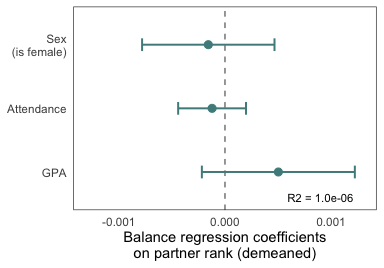

In [ ]:
balance_plot <- balance_table %>%
  mutate(label = recode(term,
                        female       = "Sex\n(is female)",
                        attendance_z = "Attendance",
                        gpa          = "GPA"),
         label = factor(label, levels = c("GPA", "Attendance", "Sex\n(is female)"))) %>%
  ggplot(aes(x = estimate, y = label)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
  geom_errorbarh(aes(xmin = conf_low, xmax = conf_high), height = 0.2,
                 color = "#4E8C8C", linewidth = 0.7) +
  geom_point(size = 2.5, color = "#4E8C8C") +
  annotate("text", x = 0.0009, y = 0.6, size = 3,
           label = sprintf("R2 = %.1e", balance_table$r2[1])) +
  scale_x_continuous(limits = c(-0.0013, 0.0013), breaks = c(-0.001, 0, 0.001)) +
  labs(x = "Balance regression coefficients\non partner rank (demeaned)", y = NULL) +
  theme_paper()

balance_plot

All three coefficients are close to zero and their confidence intervals
include zero; the $R^2$ is about $10^{-6}$. Girls and boys, and children
with high or low attendance and grades, met partners of the same
expected rank.

In [ ]:
write_csv(balance_table, here("output", "tables", "figure1d_balance.csv"))
save_figure(balance_plot, "figure1d_balance", width = 3.6, height = 2.6)

# Figure 2: four layers of one classroom

Figure 2 shows, in one small classroom (9 children), the four networks
the analysis combines:

-   **A. Friendship**: who named whom as a best friend. Green arrows are
    mutual friendships; blue arrows are one-sided.
-   **B. Popularity** and **C. non-popularity**: who named whom as
    popular or as not popular. Social Rank is computed from these two
    layers.
-   **D. Tokens**: every transfer in the game, darker for more tokens.

The same child keeps the same position in all four layers, so one can
follow how a child who is central in one layer fares in the others.

In [ ]:
library(tidyverse)
library(igraph)
library(ggraph)
library(patchwork)
library(here)
source(here("code", "00_style.R"))

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

In [ ]:
example_class <- 16

class_students <- students %>%
  filter(class_id == example_class) %>%
  mutate(name = as.character(student_id),
         sex  = if_else(female == 1, "Female", "Male"))

class_dyads <- dyads %>%
  filter(class_id == example_class) %>%
  mutate(from = as.character(sender_id), to = as.character(receiver_id))

nrow(class_students)   # 9 children
## [1] 9
nrow(class_dyads)      # 72 directed pairs = 9 x 8
## [1] 72

To draw the four panels, we first fix one position for each child,
computed on the network that joins all four layers.

In [ ]:
# One layout for all panels. We compute it on the network that joins all
# four layers, so every child is placed close to the classmates she is
# connected with in any of them. The seed fixes the result.

all_links <- class_dyads %>%
  filter(nom_q3 == 1 | nom_q4 == 1 | nom_q5 == 1 | tokens_sent > 0)

set.seed(16)
layout_all <- graph_from_data_frame(all_links %>% select(from, to),
                                    vertices = class_students %>% select(name)) %>%
  layout_with_fr()

node_positions <- tibble(name = class_students$name,
                         x = layout_all[, 1], y = layout_all[, 2])

A small function draws one layer; it is called four times.

In [ ]:
# Draws one layer. `links` has columns from, to (and optionally a color group
# or a width); node size is given by `size_var` in the node table.

draw_layer <- function(links, nodes, size_var, size_title, edge_color = "grey40",
                       title = "") {
  network <- graph_from_data_frame(links, vertices = nodes)

  # "manual" layout: each child is drawn at her (x, y) from node_positions
  ggraph(network, layout = "manual", x = V(network)$x, y = V(network)$y) +
    geom_edge_arc(aes(color = I(edge_color_value)), strength = 0.15,
                  arrow = arrow(length = unit(2, "mm"), type = "closed"),
                  end_cap = circle(3.5, "mm"), width = 0.5) +
    geom_node_point(aes(size = .data[[size_var]], fill = sex),
                    shape = 21, color = "grey20") +
    scale_fill_manual(values = c(Female = color_female, Male = color_male)) +
    scale_size_continuous(range = c(2, 9)) +
    guides(fill = guide_legend(override.aes = list(size = 4))) +
    coord_fixed(xlim = range(node_positions$x) + c(-0.3, 0.3),
                ylim = range(node_positions$y) + c(-0.3, 0.3)) +
    labs(title = title, size = size_title, fill = "Sex") +
    theme_void() +
    theme(plot.title = element_text(face = "bold"),
          legend.position = "right",
          legend.key.size = unit(3, "mm"),
          legend.text = element_text(size = 7),
          legend.title = element_text(size = 8))
}

Node size is the number of nominations received in A–C and the number of
tokens received in D.

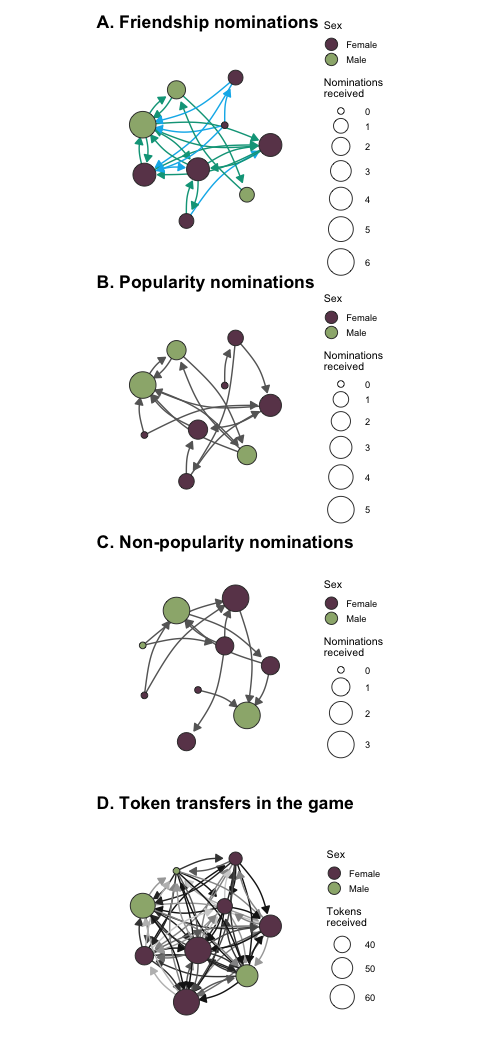

In [ ]:
# Nominations received in each question (in-degree) give the node size in A-C
in_degree <- function(question) {
  class_dyads %>%
    group_by(name = to) %>%
    summarise(value = sum(.data[[question]]))
}

nodes <- class_students %>%
  select(name, sex) %>%
  left_join(node_positions, by = "name") %>%
  left_join(in_degree("nom_q3") %>% rename(friend_in = value),   by = "name") %>%
  left_join(in_degree("nom_q4") %>% rename(popular_in = value),  by = "name") %>%
  left_join(in_degree("nom_q5") %>% rename(unpopular_in = value), by = "name") %>%
  left_join(class_dyads %>% group_by(name = to) %>%
              summarise(tokens_in = sum(tokens_sent)), by = "name")

# A. Friendship: green if the nomination is mutual, blue if one-way
friend_links <- class_dyads %>%
  filter(nom_q3 == 1) %>%
  left_join(class_dyads %>% select(from = to, to = from, back = nom_q3),
            by = c("from", "to")) %>%
  transmute(from, to,
            edge_color_value = if_else(back == 1, color_mutual, color_asymmetric))

panel_a <- draw_layer(friend_links, nodes, "friend_in", "Nominations\nreceived",
                      title = "A. Friendship nominations")

# B. Popularity and C. non-popularity: grey arrows
popular_links <- class_dyads %>%
  filter(nom_q4 == 1) %>%
  transmute(from, to, edge_color_value = "grey40")

unpopular_links <- class_dyads %>%
  filter(nom_q5 == 1) %>%
  transmute(from, to, edge_color_value = "grey40")

panel_b <- draw_layer(popular_links, nodes, "popular_in", "Nominations\nreceived",
                      title = "B. Popularity nominations")
panel_c <- draw_layer(unpopular_links, nodes, "unpopular_in", "Nominations\nreceived",
                      title = "C. Non-popularity nominations")

# D. Tokens: one arrow per transfer of at least one token; darker = more tokens
token_links <- class_dyads %>%
  filter(tokens_sent > 0) %>%
  transmute(from, to,
            edge_color_value = grey(1 - 0.08 * tokens_sent - 0.1))  # 1 token light, 10 dark

panel_d <- draw_layer(token_links, nodes, "tokens_in", "Tokens\nreceived",
                      title = "D. Token transfers in the game")

panel_a + panel_b + panel_c + panel_d + plot_layout(ncol = 1)

## The assembled figure

The published figure shows the same four layers as tilted planes stacked
on top of each other, with one legend. The node positions are the ones
chosen for that drawing (`data/raw/figure2_layout.csv`); they are a
drawing choice and play no role in any calculation. Each plane is the
layout stretched, flattened and slanted.

In [ ]:
# The assembled version of Figure 2 (as in the paper): the four layers are
# drawn as tilted planes stacked on top of each other, with one legend.
#
# The node positions are the ones chosen for the paper (data/raw/figure2_layout.csv,
# a drawing choice only). Each layer is then "tilted": a point (x, y) of a
# layer is drawn at
#
#     X = width * x + tilt * y  (stretch, and shift right when higher up)
#     Y = height * y + center   (flatten and move the plane to its row)

paper_layout <- read_csv(here("data", "raw", "figure2_layout.csv"), show_col_types = FALSE) %>%
  mutate(name = as.character(student_id))

width  <- 1.55   # how wide the planes are
tilt   <- 0.25   # how slanted the planes are
height <- 0.36   # how flat the planes are
layers <- tibble(
  layer  = c("A", "B", "C", "D"),
  title  = c("A. Friendship nominations", "B. Popularity nominations",
             "C. Non-popularity nominations", "D. Token transfers in the game"),
  center = c(4.05, 2.7, 1.35, 0),                         # rows, from top to bottom
  color  = c(color_mutual, "#1F3A5F", "#C95A3A", "grey20")
)

to_screen <- function(x, y, layer_center) {
  tibble(X = width * x + tilt * y, Y = height * y + layer_center)
}

# Frame of each plane: the rectangle [-1.2, 1.2] x [-1.3, 1.3], tilted
frames <- layers %>%
  rowwise() %>%
  reframe(layer, color,
          to_screen(c(-1.2, 1.2, 1.2, -1.2), c(-1.3, -1.3, 1.3, 1.3), center))

Nodes and arrows of the four planes. Mutual friendships are drawn once,
with two heads.

In [ ]:
# Nodes of the four layers, with their size: nominations received in A-C and
# tokens received in D (point size grows with the square root, as an area)
node_size <- function(value, max_value) 1.5 + 5 * sqrt(value / max_value)

layer_nodes <- nodes %>%
  select(name, sex, A = friend_in, B = popular_in, C = unpopular_in, D = tokens_in) %>%
  pivot_longer(A:D, names_to = "layer", values_to = "value") %>%
  left_join(paper_layout %>% select(name, x, y), by = "name") %>%
  left_join(layers, by = "layer") %>%
  group_by(layer) %>%
  mutate(size = if_else(layer == "D", node_size(value, 70), node_size(value, max(value)))) %>%
  ungroup() %>%
  mutate(to_screen(x, y, center))

# Arrows of the four layers. In A, a mutual friendship is drawn once with
# two heads (green); a one-way nomination with one head (blue).
mutual_pairs <- friend_links %>% filter(edge_color_value == color_mutual)

layer_arrows <- bind_rows(
  mutual_pairs %>% filter(from < to) %>% mutate(layer = "A", ends = "both"),
  friend_links %>% filter(edge_color_value != color_mutual) %>% mutate(layer = "A", ends = "last"),
  popular_links   %>% mutate(layer = "B", ends = "last"),
  unpopular_links %>% mutate(layer = "C", ends = "last"),
  token_links     %>% mutate(layer = "D", ends = "last")
) %>%
  left_join(paper_layout %>% select(from = name, x0 = x, y0 = y), by = "from") %>%
  left_join(paper_layout %>% select(to = name, x1 = x, y1 = y), by = "to") %>%
  left_join(layers %>% select(layer, center), by = "layer") %>%
  # stop the arrows a little before the nodes
  mutate(x0s = x0 + 0.12 * (x1 - x0), y0s = y0 + 0.12 * (y1 - y0),
         x1s = x1 - 0.12 * (x1 - x0), y1s = y1 - 0.12 * (y1 - y0),
         X0 = width * x0s + tilt * y0s, Y0 = height * y0s + center,
         X1 = width * x1s + tilt * y1s, Y1 = height * y1s + center)

In [ ]:
# The legend is drawn under the bottom plane, in the same coordinates
legend_y <- -0.8
sex_key   <- tibble(X = -1.9, Y = legend_y - c(0.25, 0.45), sex = c("Female", "Male"))
size_key  <- tibble(X = 0.55, Y = legend_y - c(0.38, 0.6, 0.86), tokens = c(30, 50, 70)) %>%
  mutate(size = node_size(tokens, 70))
gray_key  <- tibble(X = 1.55, Y = legend_y - c(0.38, 0.6, 0.82), tokens = c(1, 5, 10)) %>%
  mutate(color = grey(1 - 0.08 * tokens - 0.1))

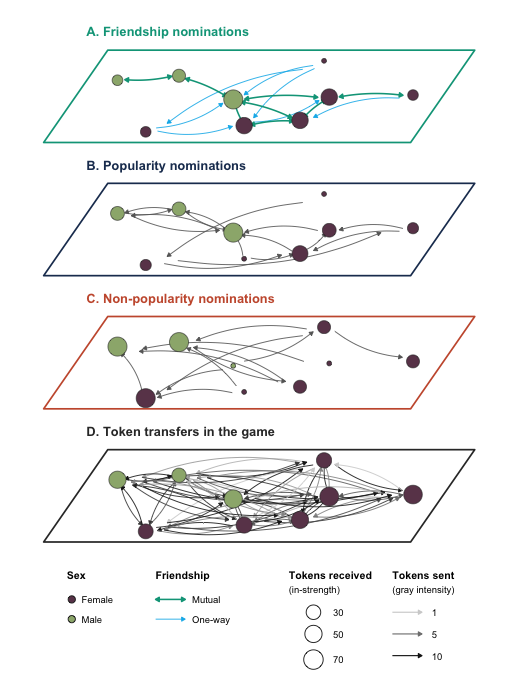

In [ ]:
arrow_head <- arrow(length = unit(1.1, "mm"), type = "closed")

figure2_assembled <- ggplot() +
  # planes and titles
  geom_polygon(data = frames, aes(X, Y, group = layer, color = I(color)),
               fill = "white", linewidth = 0.6) +
  geom_text(data = layers, aes(x = -1.75, y = center + 0.66, label = title, color = I(color)),
            hjust = 0, fontface = "bold", size = 3.4) +
  # arrows (one geom per kind of arrow head)
  geom_curve(data = filter(layer_arrows, ends == "last"),
             aes(x = X0, y = Y0, xend = X1, yend = Y1, color = I(edge_color_value)),
             curvature = 0.15, linewidth = 0.3, arrow = arrow_head) +
  geom_curve(data = filter(layer_arrows, ends == "both"),
             aes(x = X0, y = Y0, xend = X1, yend = Y1, color = I(edge_color_value)),
             curvature = 0.08, linewidth = 0.55,
             arrow = arrow(length = unit(1.1, "mm"), type = "closed", ends = "both")) +
  # children
  geom_point(data = layer_nodes, aes(X, Y, size = I(size), fill = sex),
             shape = 21, color = "grey15", stroke = 0.3) +
  # legend: sex
  annotate("text", x = -1.95, y = legend_y, label = "Sex", hjust = 0, fontface = "bold", size = 2.8) +
  geom_point(data = sex_key, aes(X, Y, fill = sex), shape = 21, size = 2.2, color = "grey15") +
  annotate("text", x = -1.8, y = sex_key$Y, label = sex_key$sex, hjust = 0, size = 2.5) +
  # legend: friendship
  annotate("text", x = -1.05, y = legend_y, label = "Friendship", hjust = 0, fontface = "bold", size = 2.8) +
  annotate("segment", x = -1.05, xend = -0.75, y = legend_y - 0.25, yend = legend_y - 0.25,
           color = color_mutual, linewidth = 0.55,
           arrow = arrow(length = unit(1.1, "mm"), type = "closed", ends = "both")) +
  annotate("segment", x = -1.05, xend = -0.75, y = legend_y - 0.45, yend = legend_y - 0.45,
           color = color_asymmetric, linewidth = 0.3, arrow = arrow_head) +
  annotate("text", x = -0.68, y = legend_y - c(0.25, 0.45), label = c("Mutual", "One-way"),
           hjust = 0, size = 2.5) +
  # legend: tokens received (node size) and tokens sent (gray)
  annotate("text", x = 0.3, y = legend_y, label = "Tokens received", hjust = 0, fontface = "bold", size = 2.8) +
  geom_point(data = size_key, aes(X, Y, size = I(size)), shape = 21, fill = "white", color = "grey15") +
  annotate("text", x = 0.75, y = size_key$Y, label = size_key$tokens, hjust = 0, size = 2.5) +
  annotate("text", x = 0.3, y = legend_y - 0.15, label = "(in-strength)", hjust = 0, size = 2.5) +
  annotate("text", x = 1.35, y = legend_y, label = "Tokens sent", hjust = 0, fontface = "bold", size = 2.8) +
  annotate("text", x = 1.35, y = legend_y - 0.15, label = "(gray intensity)", hjust = 0, size = 2.5) +
  geom_segment(data = gray_key, aes(x = X - 0.2, xend = X + 0.1, y = Y, yend = Y, color = I(color)),
               linewidth = 0.4, arrow = arrow_head) +
  annotate("text", x = 1.75, y = gray_key$Y, label = gray_key$tokens, hjust = 0, size = 2.5) +
  scale_fill_manual(values = c(Female = color_female, Male = color_male), guide = "none") +
  coord_fixed(clip = "off") +
  theme_void()

figure2_assembled

In [ ]:
save_figure(figure2_assembled, "figure2_assembled", width = 5.4, height = 7.2)
save_figure(panel_a, "figure2_panel_A", width = 5, height = 3)
save_figure(panel_b, "figure2_panel_B", width = 5, height = 3)
save_figure(panel_c, "figure2_panel_C", width = 5, height = 3)
save_figure(panel_d, "figure2_panel_D", width = 5, height = 3)

# Figure 3: the exchanges behind the regressions

Table 1 summarizes the rank gradient in one number per sample. Figure 3
shows the data behind it, in three columns, separately for non-friends
(row I), mutual friends (row II) and one-sided friendships (row III):

-   **A. What pairs exchange.** For each pair, the two transfers (what
    $i$ sent to $j$ and what $j$ sent to $i$) form one cell of an 11 ×
    11 grid. The heatmap shows the share of pairs in each cell. Since
    the order of the two children does not matter, the grid is folded
    into a triangle. Outlined regions mark low or no cooperation, very
    unequal exchanges, and full mutual cooperation (both send 10).
-   **B. Tokens sent and received along the rank gap.** Average tokens
    sent (rhombi) and received (squares), in seven equal-width bins of
    the Social Rank GAP; the area between the two curves is the
    Cooperation GAP.
-   **C. The Cooperation GAP along the rank gap.** The difference
    itself, from the observed data (solid) and from the null-model
    filtered data (semi-transparent; see the first page).

In [ ]:
library(tidyverse)
library(here)
source(here("code", "00_style.R"))

dyads <- read_csv(here("data", "generated", "analysis_dyads.csv"), show_col_types = FALSE)

## Panel A: what pairs exchange

In [ ]:
# Panel A. Every pair exchanges two numbers: what i sends to j and what j
# sends to i. The order does not matter for the heatmap (5 and 2 is the same
# pair as 2 and 5), so we keep the larger number on the x axis and the
# smaller on the y axis. That is why the heatmap is a triangle.
#
# One-sided friendships appear twice in the data (as "Sender declares" from
# one side and "Receiver declares" from the other), so for the heatmap we put
# both together in one "Asymmetric" group. Percentages are computed within
# each group.

heatmap_cells <- dyads %>%
  mutate(group = case_when(friendship == "Non-friends" ~ "Non-friends",
                           friendship == "Mutual"      ~ "Mutual friends",
                           TRUE                        ~ "Asymmetric"),
         high = pmax(tokens_sent, tokens_received),
         low  = pmin(tokens_sent, tokens_received)) %>%
  count(group, high, low) %>%
  group_by(group) %>%
  mutate(percent = 100 * n / sum(n)) %>%
  ungroup() %>%
  # add the combinations that never happened, with 0%
  complete(group, high = 0:10, low = 0:10, fill = list(n = 0, percent = 0)) %>%
  filter(low <= high)

# Three regions highlighted in the paper
heatmap_regions <- heatmap_cells %>%
  group_by(group) %>%
  summarise(
    low_cooperation  = sum(percent[high <= 1]),                 # both sent 0 or 1 (magenta)
    asymmetric       = sum(percent[high == 10 & low <= 5]),     # one sent 10, the other 5 or less (blue)
    full_cooperation = sum(percent[high == 10 & low == 10])     # both sent 10 (black)
  )

heatmap_regions

group,low_cooperation,asymmetric,full_cooperation
Asymmetric,5.076923,28.53846,14.615385
Mutual friends,2.639752,22.82609,28.416149
Non-friends,11.971831,22.99511,6.438632


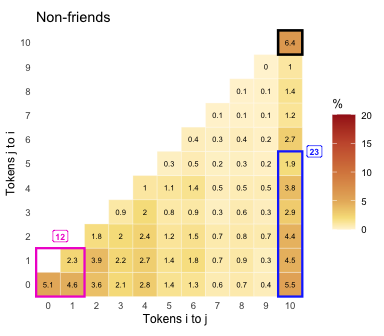

In [ ]:
plot_heatmap <- function(this_group) {
  cells   <- heatmap_cells   %>% filter(group == this_group)
  regions <- heatmap_regions %>% filter(group == this_group)

  ggplot(cells, aes(x = high, y = low, fill = percent)) +
    geom_tile(color = "white") +
    geom_text(aes(label = round(percent, 1)), size = 2) +
    # magenta: low or no cooperation
    annotate("rect", xmin = -0.5, xmax = 1.5, ymin = -0.5, ymax = 1.5,
             color = "#F000D0", fill = NA, linewidth = 0.8) +
    annotate("label", x = 0.5, y = 2, label = round(regions$low_cooperation, 1),
             color = "#F000D0", size = 2.3, fontface = "bold") +
    # blue: highly asymmetric
    annotate("rect", xmin = 9.5, xmax = 10.5, ymin = -0.5, ymax = 5.5,
             color = "#173BFF", fill = NA, linewidth = 0.8) +
    annotate("label", x = 11, y = 5.5, label = round(regions$asymmetric, 1),
             color = "#173BFF", size = 2.3, fontface = "bold") +
    # black: full mutual cooperation
    annotate("rect", xmin = 9.5, xmax = 10.5, ymin = 9.5, ymax = 10.5,
             color = "black", fill = NA, linewidth = 0.9) +
    scale_fill_gradientn(colours = c("#FFF4D6", "#F7E08A", "#E7B56A", "#D9874C", "#C95A3A", "#A51C1C"),
                         values = scales::rescale(c(0, 2, 5, 10, 15, 20)),
                         limits = c(0, 20), oob = scales::squish, name = "%") +
    scale_x_continuous(breaks = 0:10, expand = c(0, 0)) +
    scale_y_continuous(breaks = 0:10, expand = c(0, 0)) +
    coord_fixed(clip = "off") +
    labs(x = "Tokens i to j", y = "Tokens j to i", title = this_group) +
    theme_paper(base_size = 9) +
    theme(panel.border = element_blank(), legend.position = "right")
}

plot_heatmap("Non-friends")

## Panels B and C: exchanges along the Social Rank GAP

Each child counts once. For each child we average her exchanges with the
partners in the group and take the median rank gap of those partners.
The children are then grouped into seven equal-width bins of that median
rank gap, and each point is the average across the children of a bin,
with a 95% confidence interval.

In [ ]:
# Panels B and C follow the logic of the original analysis:
#   1. for each child (sender), average over her partners in a given
#      friendship group: tokens sent, tokens received, Cooperation GAP, and
#      the median Social Rank GAP of those partners;
#   2. split children into 7 equal-width bins of that median rank gap;
#      (children whose transfers were all removed by the filter drop out of
#      the filtered version, but the bins stay the same)
#   3. in each bin, average across children, with a 95% confidence interval
#      (mean +/- 1.96 * SD / sqrt(n)).
#
# Panel C repeats this with the null-model filtered tokens (only transfers
# that depart most from each child's usual giving; see 01_build_measures.R).

binned_means <- function(data, sent, received, version) {
  data %>%
    group_by(sender_id) %>%
    summarise(gap      = median(rank_gap),
              sent     = mean({{ sent }}, na.rm = TRUE),
              received = mean({{ received }}, na.rm = TRUE),
              coop_gap = mean({{ received }} - {{ sent }}, na.rm = TRUE)) %>%
    # bins are defined with all children, so the observed and the filtered
    # versions use exactly the same bins
    mutate(bin = cut_interval(gap, 7)) %>%
    filter(!is.na(coop_gap)) %>%
    group_by(bin) %>%
    summarise(gap           = mean(gap),
              n             = n(),
              mean_sent     = mean(sent),
              ci_sent       = 1.96 * sd(sent) / sqrt(n),
              mean_received = mean(received),
              ci_received   = 1.96 * sd(received) / sqrt(n),
              mean_coop_gap = mean(coop_gap),
              ci_coop_gap   = 1.96 * sd(coop_gap) / sqrt(n)) %>%
    mutate(version = version)
}

rank_groups <- c("Non-friends", "Mutual", "Sender declares")

binned <- map_dfr(rank_groups, function(this_group) {
  group_data <- dyads %>% filter(friendship == this_group)
  bind_rows(
    binned_means(group_data, tokens_sent, tokens_received, "Observed"),
    binned_means(group_data, tokens_sent_filtered, tokens_received_filtered, "Filtered")
  ) %>%
    mutate(group = this_group)
})

binned %>% filter(group == "Non-friends", version == "Observed")

bin,gap,n,mean_sent,ci_sent,mean_received,ci_received,mean_coop_gap,ci_coop_gap,version,group
"[-0.911,-0.654]",-0.7550028,7,5.388853,1.9871675,3.714069,1.1125837,-1.6747835,1.7077605,Observed,Non-friends
"(-0.654,-0.397]",-0.4919824,50,5.008796,0.7122451,3.753436,0.4268704,-1.2553605,0.7040243,Observed,Non-friends
"(-0.397,-0.14]",-0.2392920,162,4.964609,0.3933742,3.927462,0.2218309,-1.0371466,0.4171635,Observed,Non-friends
"(-0.14,0.117]",-0.0156467,347,4.228131,0.2551387,4.408465,0.1447495,0.1803341,0.2571122,Observed,Non-friends
"(0.117,0.374]",0.2197450,172,4.385789,0.3622750,4.770044,0.2222489,0.3842549,0.3394136,Observed,Non-friends
"(0.374,0.632]",0.4898983,92,3.949870,0.4749754,5.258546,0.3658204,1.3086766,0.4132577,Observed,Non-friends
"(0.632,0.889]",0.7148694,29,4.286103,0.8741164,5.611288,0.3886832,1.3251842,0.9127813,Observed,Non-friends


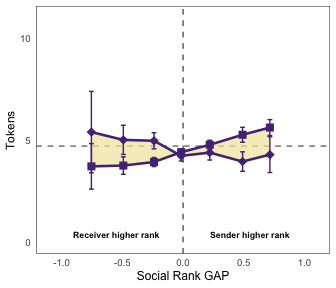

In [ ]:
mean_tokens <- mean(dyads$tokens_sent)   # dashed horizontal line: overall mean

plot_tokens <- function(this_group, color) {
  bins <- binned %>% filter(group == this_group, version == "Observed")

  ggplot(bins, aes(x = gap)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
    geom_hline(yintercept = mean_tokens, linetype = "dashed", color = "grey50") +
    # yellow area between the two lines = the Cooperation GAP
    geom_ribbon(aes(ymin = mean_received, ymax = mean_sent), fill = "#F0E5A8", alpha = 0.7) +
    # sent: rhombi
    geom_line(aes(y = mean_sent), color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_sent - ci_sent, ymax = mean_sent + ci_sent),
                  color = color, width = 0.04) +
    geom_point(aes(y = mean_sent), color = color, shape = 18, size = 3) +
    # received: squares
    geom_line(aes(y = mean_received), color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_received - ci_received, ymax = mean_received + ci_received),
                  color = color, width = 0.04) +
    geom_point(aes(y = mean_received), color = color, shape = 15, size = 2.5) +
    annotate("text", x = c(-0.55, 0.55), y = 0.4, size = 2.3, fontface = "bold",
             label = c("Receiver higher rank", "Sender higher rank")) +
    scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(limits = c(0, 11), breaks = c(0, 5, 10)) +
    labs(x = "Social Rank GAP", y = "Tokens") +
    theme_paper(base_size = 9)
}

plot_tokens("Non-friends", color_non_friends)

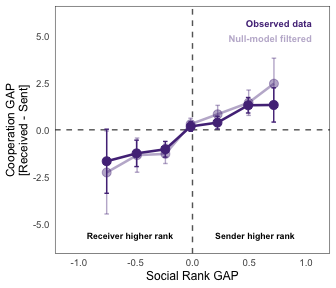

In [ ]:
plot_coop_gap <- function(this_group, color, y_limits = c(-6, 6)) {
  bins <- binned %>% filter(group == this_group)

  ggplot(bins, aes(x = gap, y = mean_coop_gap, alpha = version)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
    geom_hline(yintercept = 0, linetype = "dashed", color = "grey40") +
    geom_line(color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_coop_gap - ci_coop_gap, ymax = mean_coop_gap + ci_coop_gap),
                  color = color, width = 0.04) +
    geom_point(color = color, size = 2.8) +
    scale_alpha_manual(values = c(Observed = 1, Filtered = 0.4)) +
    annotate("text", x = c(-0.55, 0.55), y = y_limits[1] + 0.4, size = 2.3, fontface = "bold",
             label = c("Receiver higher rank", "Sender higher rank")) +
    annotate("text", x = 1.05, y = y_limits[2] - c(0.3, 1.1), hjust = 1, size = 2.5,
             fontface = "bold", color = color, alpha = c(1, 0.4),
             label = c("Observed data", "Null-model filtered")) +
    scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(limits = y_limits, breaks = seq(-7.5, 5, 2.5)) +
    labs(x = "Social Rank GAP", y = "Cooperation GAP\n[Received - Sent]") +
    theme_paper(base_size = 9)
}

plot_coop_gap("Non-friends", color_non_friends)

Among non-friends, the two curves cross: a child who meets a
higher-ranked classmate (left side) sends more than she receives; one
who meets a lower-ranked classmate (right side) receives more than she
sends. So the Cooperation GAP rises from negative to positive. Among
mutual friends both curves are higher (more giving overall) and they
nearly overlap, so the Cooperation GAP stays close to zero along the
whole range.

## All nine panels

In [ ]:
rows <- tribble(
  ~row,  ~heatmap_group,   ~rank_group,       ~color,            ~y_min,
  "I",   "Non-friends",    "Non-friends",     color_non_friends, -6,
  "II",  "Mutual friends", "Mutual",          color_mutual,      -6,
  "III", "Asymmetric",     "Sender declares", color_asymmetric,  -8.5
)

for (k in seq_len(nrow(rows))) {
  r <- rows[k, ]
  save_figure(plot_heatmap(r$heatmap_group),
              paste0("figure3_", r$row, "_A_heatmap"), width = 3.6, height = 3.2)
  save_figure(plot_tokens(r$rank_group, r$color),
              paste0("figure3_", r$row, "_B_tokens"), width = 3.2, height = 3)
  save_figure(plot_coop_gap(r$rank_group, r$color, y_limits = c(r$y_min, 6)),
              paste0("figure3_", r$row, "_C_coop_gap"), width = 3.2, height = 3)
}

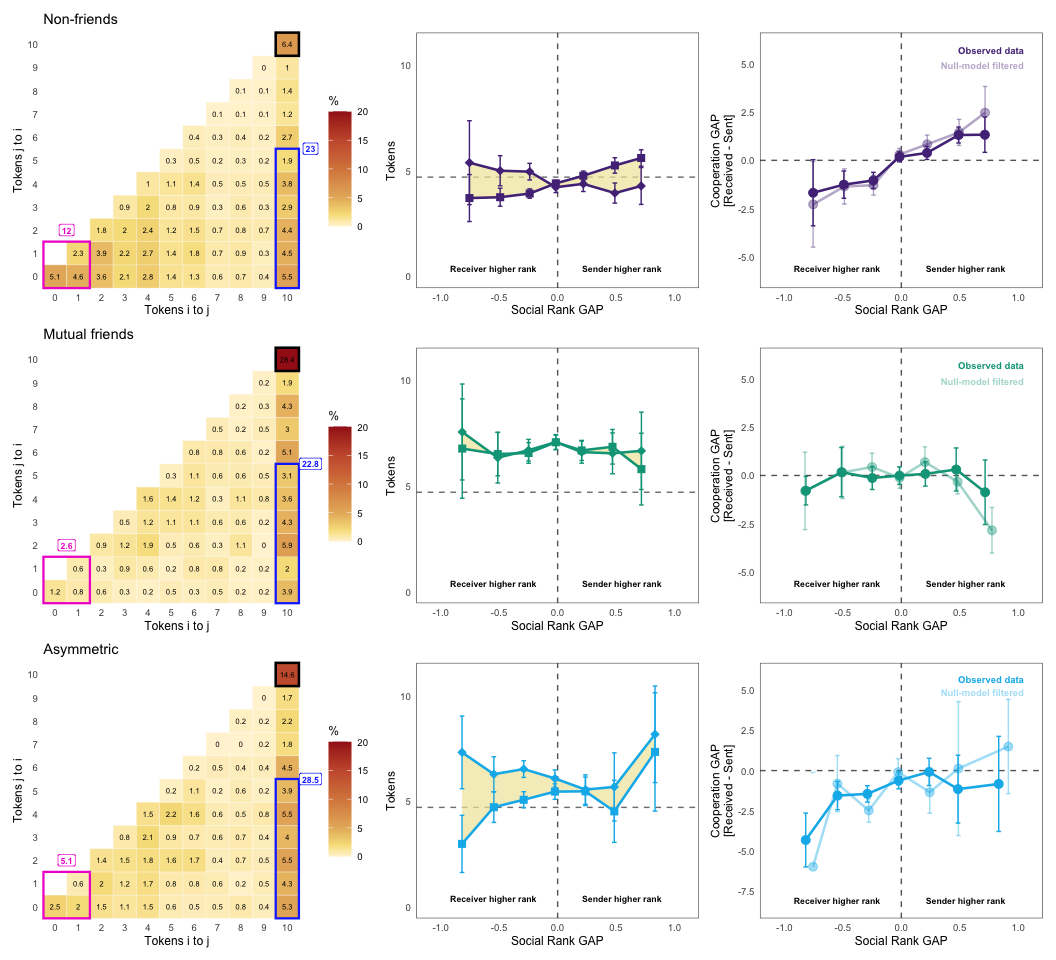

In [ ]:
library(patchwork)
(plot_heatmap("Non-friends")    | plot_tokens("Non-friends", color_non_friends)    | plot_coop_gap("Non-friends", color_non_friends)) /
(plot_heatmap("Mutual friends") | plot_tokens("Mutual", color_mutual)              | plot_coop_gap("Mutual", color_mutual)) /
(plot_heatmap("Asymmetric")     | plot_tokens("Sender declares", color_asymmetric) | plot_coop_gap("Sender declares", color_asymmetric, c(-8.5, 6)))

In [ ]:
write_csv(heatmap_cells, here("output", "tables", "figure3_heatmap_cells.csv"))
write_csv(binned,        here("output", "tables", "figure3_binned_means.csv"))

# Other numbers in the text

The remaining numbers quoted in the text are computed here, grouped by
topic. Each block of code says where in the text the number appears.

**Sample and design.** Size of the sample, number of decisions per child
and rounds per classroom.

In [ ]:
library(tidyverse)
library(lfe)
library(igraph)
library(here)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE) %>%
  mutate(class_round = paste(class_id, round, sep = "_"))
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)
table1   <- read_csv(here("output", "tables", "table1.csv"),  show_col_types = FALSE)

numbers <- list()   # we collect everything here and save it at the end

In [ ]:
# Abstract, Results and Methods: who took part
numbers$children   <- nrow(students)
numbers$classrooms <- n_distinct(students$class_id)
numbers$schools    <- n_distinct(students$school_id)
numbers$decisions  <- nrow(dyads)
numbers$percent_female <- 100 * mean(students$female)
# two computed ages above 15 are birth-date errors and are left out (as in the SI)
valid_age <- students$age[!is.na(students$age) & students$age <= 15]
numbers$age_mean   <- mean(valid_age)
numbers$age_sd     <- sd(valid_age)

numbers[c("children", "classrooms", "schools", "decisions",
          "percent_female", "age_mean", "age_sd")]
## $children
## [1] 859
## 
## $classrooms
## [1] 45
## 
## $schools
## [1] 14
## 
## $decisions
## [1] 17804
## 
## $percent_female
## [1] 57.2759
## 
## $age_mean
## [1] 10.05088
## 
## $age_sd
## [1] 1.01552

In [ ]:
# Methods, "Random assignment of dyadic partners"
decisions_per_child <- dyads %>% count(sender_id)
rounds_per_class    <- dyads %>% group_by(class_id) %>% summarise(rounds = n_distinct(round))

numbers$decisions_per_child_min  <- min(decisions_per_child$n)
numbers$decisions_per_child_max  <- max(decisions_per_child$n)
numbers$decisions_per_child_mean <- mean(decisions_per_child$n)
numbers$rounds_per_class_min     <- min(rounds_per_class$rounds)
numbers$rounds_per_class_max     <- max(rounds_per_class$rounds)
numbers$rounds_per_class_mean    <- mean(rounds_per_class$rounds)

# Each pair of classmates met only once: count unordered pairs and check that
# no pair appears in more than one round
pairs <- dyads %>%
  mutate(child_a = pmin(sender_id, receiver_id),
         child_b = pmax(sender_id, receiver_id)) %>%
  group_by(child_a, child_b) %>%
  summarise(decisions = n(), rounds = n_distinct(round), .groups = "drop")

numbers$unordered_pairs        <- nrow(pairs)
numbers$pairs_in_several_rounds <- sum(pairs$rounds > 1)
numbers$pairs_with_two_decisions <- sum(pairs$decisions == 2)

numbers[str_detect(names(numbers), "per_|pairs")]
## $decisions_per_child_min
## [1] 6
## 
## $decisions_per_child_max
## [1] 38
## 
## $decisions_per_child_mean
## [1] 20.72643
## 
## $rounds_per_class_min
## [1] 7
## 
## $rounds_per_class_max
## [1] 43
## 
## $rounds_per_class_mean
## [1] 23.93333
## 
## $unordered_pairs
## [1] 8902
## 
## $pairs_in_several_rounds
## [1] 0
## 
## $pairs_with_two_decisions
## [1] 8902

**Friendship.** Share of non-friend, mutual and one-sided pairs.

In [ ]:
# Results and Fig. 3 legend: share of each relationship type
friendship_shares <- dyads %>%
  mutate(type = if_else(friendship %in% c("Sender declares", "Receiver declares"),
                        "Asymmetric", friendship)) %>%
  count(type) %>%
  mutate(percent = 100 * n / sum(n))

friendship_shares

type,n,percent
Asymmetric,2600,14.603460
Mutual,1288,7.234329
Non-friends,13916,78.162211


**Rank differences children actually meet.** The full range of the rank
gap (from bottom to top of a classroom) occurs for only one pair per
classroom. This block looks at a more common contrast: pairs between a
child in the top quarter of the classroom ranking and one in the bottom
quarter, and the Cooperation GAP that Table 1 predicts for them.

In [ ]:
# Results: "a top- versus bottom-quartile pairing, about 13% of interactions,
# implies roughly 1.8 tokens".
# Quartiles of Social Rank are computed over all senders and receivers.
quartile_cuts <- quantile(c(dyads$sender_rank, dyads$receiver_rank), c(0.25, 0.50, 0.75))

to_quartile <- function(rank) {
  case_when(rank <= quartile_cuts[1] ~ 1,
            rank <= quartile_cuts[2] ~ 2,
            rank <= quartile_cuts[3] ~ 3,
            TRUE ~ 4)
}

dyads <- dyads %>%
  mutate(sender_quartile   = to_quartile(sender_rank),
         receiver_quartile = to_quartile(receiver_rank))

beta_all <- table1$beta[table1$sample == "All dyads"]

top_to_bottom <- dyads %>% filter(sender_quartile == 4, receiver_quartile == 1)

# share of pairs between the top and the bottom quartile (in either direction),
# computed in each classroom and then averaged over the 45 classrooms
numbers$percent_top_vs_bottom_pairs <- dyads %>%
  group_by(class_id) %>%
  summarise(share = mean(abs(sender_quartile - receiver_quartile) == 3)) %>%
  summarise(100 * mean(share)) %>%
  pull()
numbers$predicted_coop_gap_top_to_bottom <- beta_all * mean(top_to_bottom$rank_gap)
numbers$observed_coop_gap_top_to_bottom  <- mean(top_to_bottom$coop_gap)

**Filtered analysis.** The Table 1 model on the null-model filtered
sample.

In [ ]:
# Results and Methods: null-model filtered regressions (Fig. 3C, SI tables)
numbers$percent_transfers_kept <- 100 * mean(!is.na(dyads$tokens_sent_filtered))
numbers$percent_dyads_kept     <- 100 * mean(!is.na(dyads$coop_gap_filtered))

filtered_slope <- function(data) {
  model <- felm(coop_gap_filtered ~ rank_gap | sender_id + class_round | 0 | class_id,
                data = data %>% filter(!is.na(coop_gap_filtered)))
  summary(model)$coefficients["rank_gap", ]
}

filtered_all <- filtered_slope(dyads)
filtered_non <- filtered_slope(dyads %>% filter(friendship == "Non-friends"))
filtered_mut <- filtered_slope(dyads %>% filter(friendship == "Mutual"))

rbind(all = filtered_all, non_friends = filtered_non, mutual = filtered_mut)
##             Estimate Cluster s.e.  t value     Pr(>|t|)
## all         3.426206    0.5027504 6.814925 2.136083e-08
## non_friends 3.411520    0.6542668 5.214264 4.737232e-06
## mutual      5.167229    3.4629386 1.492152 1.472527e-01

numbers$filtered_slope_all         <- filtered_all[["Estimate"]]
numbers$filtered_slope_non_friends <- filtered_non[["Estimate"]]
numbers$filtered_p_non_friends     <- filtered_non[["Pr(>|t|)"]]
numbers$filtered_slope_mutual      <- filtered_mut[["Estimate"]]

**One-sided friendships.** How often the exchanges fall in each region
of Figure 3A.

In [ ]:
# Results, "Directional effects in asymmetric friendships": one-sided pairs
asymmetric <- dyads %>% filter(friendship == "Sender declares")   # each pair once

numbers$percent_full_cooperation_asym <-
  100 * mean(asymmetric$tokens_sent == 10 & asymmetric$tokens_received == 10)
# "one student sent at least five tokens more than they received"
numbers$percent_strongly_asymmetric_asym <-
  100 * mean(abs(asymmetric$tokens_sent - asymmetric$tokens_received) >= 5)
# the blue region of the heatmap (one sent 10, the other 5 or less)
numbers$percent_blue_region_asym <-
  100 * mean(pmax(asymmetric$tokens_sent, asymmetric$tokens_received) == 10 &
             pmin(asymmetric$tokens_sent, asymmetric$tokens_received) <= 5)

**A rank read off the game.** Instead of nominations, rank can be
computed from the token network itself (PageRank on who gives to whom).
This block correlates that behavioral rank with the nomination-based
Social Rank (SI Section 9 has the full analysis).

In [ ]:
# Discussion: Behavioral Social Rank = PageRank on the network of tokens sent
# in the game, rescaled 0-1 within class. Compared with the nomination-based
# Social Rank using a Spearman correlation.
behavioral_rank <- dyads %>%
  transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id),
            weight = tokens_sent) %>%
  group_by(class_id) %>%
  group_modify(function(edges, key) {
    pr <- page_rank(graph_from_data_frame(edges, directed = TRUE))$vector
    tibble(student_id = as.numeric(names(pr)), behavioral_pagerank = pr)
  }) %>%
  mutate(behavioral_rank = (behavioral_pagerank - min(behavioral_pagerank)) /
                           (max(behavioral_pagerank) - min(behavioral_pagerank))) %>%
  ungroup() %>%
  left_join(students %>% select(student_id, social_rank), by = "student_id")

# Three versions of the correlation: (1) raw PageRank scores pooled over all
# classrooms; (2) the 0-1 ranks rescaled within each classroom, pooled; and
# (3) the median of the within-classroom correlations. Raw PageRank is
# roughly 1 / class size, so (1) also reflects differences in class size;
# (2) and (3) compare children only within their own classroom.
numbers$spearman_raw_pagerank_pooled <-
  cor(behavioral_rank$behavioral_pagerank,
      students$pagerank[match(behavioral_rank$student_id, students$student_id)],
      method = "spearman")
numbers$spearman_rescaled_ranks_pooled <-
  cor(behavioral_rank$behavioral_rank, behavioral_rank$social_rank, method = "spearman")
numbers$spearman_median_within_class <- behavioral_rank %>%
  group_by(class_id) %>%
  summarise(rho = cor(behavioral_rank, social_rank, method = "spearman")) %>%
  summarise(median(rho)) %>%
  pull()

**Response quality.** Children who named the same classmate as both
popular and not popular, and the time between consecutive decisions.

In [ ]:
# Methods, response quality.
# (1) Children who named the same classmate as both "most popular" and
#     "not popular" (questions 4 and 5).
conflicting <- dyads %>% filter(nom_q4 == 1 & nom_q5 == 1)

numbers$conflicting_popularity_pairs    <- nrow(conflicting)                 # SI: 121
numbers$children_with_conflict          <- n_distinct(conflicting$sender_id) # SI: 70 of 859
numbers$classes_with_conflict           <- n_distinct(conflicting$class_id)  # SI: 30 of 45
# each conflict involves two nominations (one in Q4, one in Q5)
numbers$percent_of_popularity_nominations <- 100 * 2 * nrow(conflicting) /
  (sum(dyads$nom_q4) + sum(dyads$nom_q5))

# (2) Time between consecutive decisions of the same child (only classes
#     where the tablets recorded the time of each decision).
intervals <- dyads %>%
  filter(!is.na(seconds_since_start)) %>%
  arrange(sender_id, seconds_since_start) %>%
  group_by(sender_id) %>%
  mutate(seconds_since_previous = seconds_since_start - lag(seconds_since_start)) %>%
  ungroup()

numbers$median_seconds_between_decisions <- median(intervals$seconds_since_previous, na.rm = TRUE)
numbers$classes_with_timing <- n_distinct(intervals$class_id)

In [ ]:
numbers_table <- tibble(quantity = names(numbers), value = unlist(numbers))
numbers_table %>% mutate(value = round(value, 3)) %>% print(n = Inf)
## # A tibble: 42 × 2
##    quantity                              value
##    <chr>                                 <dbl>
##  1 children                            859    
##  2 classrooms                           45    
##  3 schools                              14    
##  4 decisions                         17804    
##  5 percent_female                       57.3  
##  6 age_mean                             10.1  
##  7 age_sd                                1.02 
##  8 decisions_per_child_min               6    
##  9 decisions_per_child_max              38    
## 10 decisions_per_child_mean             20.7  
## 11 rounds_per_class_min                  7    
## 12 rounds_per_class_max                 43    
## 13 rounds_per_class_mean                23.9  
## 14 unordered_pairs                    8902    
## 15 pairs_in_several_rounds               0    
## 16 pairs_with_two_decisions           8902    
## 17 percent_non_friends                  78.2  
## 18 percent_mutual                        7.23 
## 19 percent_asymmetric                   14.6  
## 20 sd_rank_gap_mutual                    0.295
## 21 sd_rank_gap_non_friends               0.361
## 22 percent_top_vs_bottom_pairs          13.3  
## 23 predicted_coop_gap_top_to_bottom      1.76 
## 24 observed_coop_gap_top_to_bottom       1.54 
## 25 percent_transfers_kept               50.0  
## 26 percent_dyads_kept                   25.8  
## 27 filtered_slope_all                    3.43 
## 28 filtered_slope_non_friends            3.41 
## 29 filtered_p_non_friends                0    
## 30 filtered_slope_mutual                 5.17 
## 31 percent_full_cooperation_asym        14.6  
## 32 percent_strongly_asymmetric_asym     36.8  
## 33 percent_blue_region_asym             28.5  
## 34 spearman_raw_pagerank_pooled          0.852
## 35 spearman_rescaled_ranks_pooled        0.431
## 36 spearman_median_within_class          0.509
## 37 conflicting_popularity_pairs        121    
## 38 children_with_conflict               70    
## 39 classes_with_conflict                30    
## 40 percent_of_popularity_nominations     5.79 
## 41 median_seconds_between_decisions     44    
## 42 classes_with_timing                  29

write_csv(numbers_table, here("output", "tables", "numbers_in_text.csv"))

In [ ]:
sessionInfo()
## R version 4.3.2 (2023-10-31)
## Platform: aarch64-apple-darwin20 (64-bit)
## Running under: macOS 26.7.1
## 
## Matrix products: default
## BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
## LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0
## 
## locale:
## [1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8
## 
## time zone: America/Santiago
## tzcode source: internal
## 
## attached base packages:
## [1] stats     graphics  grDevices utils     datasets  methods   base     
## 
## other attached packages:
##  [1] patchwork_1.3.0 ggraph_2.2.1    igraph_2.1.4    lfe_3.1.1      
##  [5] Matrix_1.6-1.1  lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
##  [9] dplyr_1.1.4     purrr_1.0.4     readr_2.1.5     tidyr_1.3.1    
## [13] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0 here_1.0.1     
## 
## loaded via a namespace (and not attached):
##  [1] gtable_0.3.6       xfun_0.52          ggrepel_0.9.6      lattice_0.22-6    
##  [5] tzdb_0.5.0         vctrs_0.6.5        tools_4.3.2        generics_0.1.3    
##  [9] parallel_4.3.2     sandwich_3.1-1     pkgconfig_2.0.3    lifecycle_1.0.4   
## [13] compiler_4.3.2     farver_2.1.2       textshaping_1.0.0  munsell_0.5.1     
## [17] ggforce_0.4.2      graphlayouts_1.2.2 htmltools_0.5.8.1  yaml_2.3.10       
## [21] Formula_1.2-5      pillar_1.10.2      crayon_1.5.3       MASS_7.3-60       
## [25] cachem_1.1.0       viridis_0.6.5      tidyselect_1.2.1   digest_0.6.37     
## [29] stringi_1.8.7      labeling_0.4.3     polyclip_1.10-7    rprojroot_2.0.4   
## [33] fastmap_1.2.0      grid_4.3.2         colorspace_2.1-1   cli_3.6.4         
## [37] magrittr_2.0.3     utf8_1.2.4         tidygraph_1.3.1    withr_3.0.2       
## [41] scales_1.3.0       bit64_4.6.0-1      timechange_0.3.0   rmarkdown_2.29    
## [45] bit_4.6.0          gridExtra_2.3      ragg_1.3.3         zoo_1.8-13        
## [49] hms_1.1.3          memoise_2.0.1      evaluate_1.0.3     knitr_1.50        
## [53] viridisLite_0.4.2  rlang_1.1.6        Rcpp_1.0.14        xtable_1.8-4      
## [57] glue_1.8.0         tweenr_2.0.3       vroom_1.6.5        jsonlite_2.0.0    
## [61] R6_2.6.1           systemfonts_1.2.2